In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_openai import ChatOpenAI
from langchain_huggingface import HuggingFaceEndpoint, ChatHuggingFace
from dotenv import load_dotenv
from langgraph.checkpoint.memory import  InMemorySaver

In [2]:
class JokeState(TypedDict):
    topic: str
    joke: str
    explaination: str

In [11]:
def gen_joke(state: JokeState) -> JokeState:
    return {
        'joke': f"this is joke: {state['topic']}"
    }

def gen_exp(state: JokeState) -> JokeState:
    return {
        'explaination': f"this is explaination: {state['topic']}"
    }

In [4]:
checkpointer = InMemorySaver()

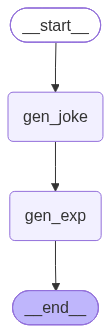

In [12]:
graph = StateGraph(JokeState)

graph.add_node('gen_joke', gen_joke)
graph.add_node('gen_exp', gen_exp)

graph.add_edge(START, 'gen_joke')
graph.add_edge('gen_joke', 'gen_exp')
graph.add_edge('gen_exp', END)


workflow = graph.compile(checkpointer=checkpointer)
workflow

In [13]:
config = {"configurable": {"thread_id": "1"}}

workflow.invoke({"topic": "Onion"}, config)

{'topic': 'Onion',
 'joke': 'this is joke: Onion',
 'explaination': 'this is explaination: Onion'}

In [14]:
config = {"configurable": {"thread_id": "2"}}

workflow.invoke({"topic": "Oranges"}, config)

{'topic': 'Oranges',
 'joke': 'this is joke: Oranges',
 'explaination': 'this is explaination: Oranges'}

In [17]:
workflow.get_state({"configurable": {"thread_id": "2"}})
workflow.get_state({"configurable": {"thread_id": "1"}})

StateSnapshot(values={'topic': 'Onion', 'joke': 'this is joke: Onion', 'explaination': 'this is explaination: Onion'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c0b43-3668-63a5-8006-e660e5a84df9'}}, metadata={'source': 'loop', 'step': 6, 'parents': {}}, created_at='2026-10-05T11:59:21.419860+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c0b43-3666-6eef-8005-b603e0c2d96c'}}, tasks=(), interrupts=())